# Notebook 03 — METEOR Lexical Evaluation

## Objective

This notebook computes the METEOR lexical evaluation score for machine
translation outputs across all datasets used in the UniMTScore framework.

## Datasets

The unified evaluation set consists of:

- FLORES-200
- IN22
- IndicMT-Eval

A total of 48,439 translation evaluation instances are processed across
12 translation directions involving English and six Indic languages:

- Gujarati
- Hindi
- Kannada
- Malayalam
- Marathi
- Odia

## Method

For each evaluation instance, the METEOR score is calculated by comparing
the machine-generated translation against the corresponding reference
translation.

The three datasets are standardized into a common schema before METEOR
calculation.

## Final Results

Total evaluation instances: 48,439

Dataset-wise mean METEOR:

- FLORES-200: 0.4722
- IN22: 0.4071
- IndicMT-Eval: 0.3809

Highest-scoring translation direction:

- Odia → English: 0.5746

Lowest-scoring translation direction:

- English → Malayalam: 0.1729

## Output

The final METEOR feature file is saved as:

`features/lexical/unified_meteor.csv`

This file contains the standardized evaluation information together with
the computed METEOR score and will be used as an input feature for subsequent
UniMTScore evaluation stages.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

In [3]:
import nltk

nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [4]:
from nltk.translate.meteor_score import meteor_score

print("METEOR imported successfully.")

METEOR imported successfully.


In [5]:
import pandas as pd
import numpy as np
from pathlib import Path
import nltk

# Project paths
PROJECT_ROOT = Path("/content/drive/MyDrive/UniMTScore")

EVAL_DIR = PROJECT_ROOT / "processed" / "evaluation_ready"
LEXICAL_DIR = PROJECT_ROOT / "features" / "lexical"

LEXICAL_DIR.mkdir(parents=True, exist_ok=True)

# Load finalized unified evaluation dataset
evaluation_data = pd.read_csv(
    EVAL_DIR / "unified_evaluation_data.csv"
)

print("Dataset shape:", evaluation_data.shape)

print("\nColumns:")
print(evaluation_data.columns.tolist())

print("\nDataset distribution:")
print(
    evaluation_data.groupby(["dataset", "subset"])
    .size()
)

print("\nMissing values:")
print(evaluation_data.isna().sum())

Dataset shape: (42288, 9)

Columns:
['evaluation_id', 'dataset', 'subset', 'source', 'reference', 'translation', 'source_language', 'target_language', 'direction']

Dataset distribution:
dataset     subset
FLORES-200  dev       11964
IN22        Conv      18036
            Gen       12288
dtype: int64

Missing values:
evaluation_id      0
dataset            0
subset             0
source             0
reference          0
translation        0
source_language    0
target_language    0
direction          0
dtype: int64


In [6]:
# ============================================================
# NOTEBOOK 03 — METEOR
# Load Unified Evaluation Dataset
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
import nltk

# Project paths
PROJECT_ROOT = Path("/content/drive/MyDrive/UniMTScore")

EVAL_DIR = PROJECT_ROOT / "processed" / "evaluation_ready"
LEXICAL_DIR = PROJECT_ROOT / "features" / "lexical"

LEXICAL_DIR.mkdir(parents=True, exist_ok=True)

# Load finalized unified evaluation dataset
evaluation_data = pd.read_csv(
    EVAL_DIR / "unified_evaluation_data.csv"
)

print("Dataset shape:", evaluation_data.shape)

print("\nColumns:")
print(evaluation_data.columns.tolist())

print("\nDataset distribution:")
print(
    evaluation_data.groupby(["dataset", "subset"])
    .size()
)

print("\nMissing values:")
print(evaluation_data.isna().sum())

Dataset shape: (42288, 9)

Columns:
['evaluation_id', 'dataset', 'subset', 'source', 'reference', 'translation', 'source_language', 'target_language', 'direction']

Dataset distribution:
dataset     subset
FLORES-200  dev       11964
IN22        Conv      18036
            Gen       12288
dtype: int64

Missing values:
evaluation_id      0
dataset            0
subset             0
source             0
reference          0
translation        0
source_language    0
target_language    0
direction          0
dtype: int64


In [7]:
print("\nTranslation directions:")
print(
    evaluation_data["direction"]
    .value_counts()
    .sort_index()
)


Translation directions:
direction
eng_Latn→guj_Gujr    3524
eng_Latn→hin_Deva    3524
eng_Latn→kan_Knda    3524
eng_Latn→mal_Mlym    3524
eng_Latn→mar_Deva    3524
eng_Latn→ory_Orya    3524
guj_Gujr→eng_Latn    3524
hin_Deva→eng_Latn    3524
kan_Knda→eng_Latn    3524
mal_Mlym→eng_Latn    3524
mar_Deva→eng_Latn    3524
ory_Orya→eng_Latn    3524
Name: count, dtype: int64


In [8]:
# ============================================================
# METEOR Calculation Function
# ============================================================

def calculate_meteor(reference, translation):

    if pd.isna(reference) or pd.isna(translation):
        return np.nan

    reference_tokens = str(reference).split()
    translation_tokens = str(translation).split()

    if len(reference_tokens) == 0 or len(translation_tokens) == 0:
        return np.nan

    score = meteor_score(
        [reference_tokens],
        translation_tokens
    )

    return score

In [9]:
# ============================================================
# Test METEOR on One Evaluation Instance
# ============================================================

sample = evaluation_data.iloc[0]

sample_score = calculate_meteor(
    sample["reference"],
    sample["translation"]
)

print("Reference:")
print(sample["reference"])

print("\nTranslation:")
print(sample["translation"])

print("\nMETEOR Score:", sample_score)

Reference:
સોમવારે, સ્ટેનફોર્ડ યુનિવર્સિટી સ્કૂલ ઓફ મેડિસિનના વૈજ્ઞાનિકોએ એક નવા નિદાન સાધનની શોધની જાહેરાત કરી હતી જે કોષોને પ્રકાર દ્વારા ક્રમમાં ગોઠવી શકે છેઃ એક નાનકડી પ્રિન્ટેબલ ચિપ કે જે સંભવતઃ એક અમેરિકન સેન્ટ માટે સ્ટાન્ડર્ડ ઇન્કજેટ પ્રિન્ટર્સનો ઉપયોગ કરીને બનાવી શકાય.

Translation:
સોમવારે, સ્ટેનફોર્ડ યુનિવર્સિટી સ્કૂલ ઓફ મેડિસિનના વૈજ્ઞાનિકોએ એક નવા નિદાન સાધનનો શોધ જાહેર કર્યો જે પ્રકાર દ્વારા કોશિકાઓને સૉર્ટ કરી શકે છેઃ એક નાનો છાપવાયોગ્ય ચિપ જે પ્રમાણભૂત ઇંકજેટ પ્રિન્ટરોનો ઉપયોગ કરીને લગભગ એક યુએસ સેન્ટ દરેક માટે બનાવી શકાય છે.

METEOR Score: 0.5760390243902439


In [10]:
# ============================================================
# Calculate METEOR for Entire Unified Evaluation Dataset
# ============================================================

from tqdm.auto import tqdm

tqdm.pandas()

evaluation_data["meteor_score"] = evaluation_data.progress_apply(
    lambda row: calculate_meteor(
        row["reference"],
        row["translation"]
    ),
    axis=1
)

print("METEOR calculation completed.")
print("Total rows:", len(evaluation_data))
print("METEOR scores calculated:", evaluation_data["meteor_score"].notna().sum())
print("Missing METEOR scores:", evaluation_data["meteor_score"].isna().sum())

  0%|          | 0/42288 [00:00<?, ?it/s]

METEOR calculation completed.
Total rows: 42288
METEOR scores calculated: 42288
Missing METEOR scores: 0


In [11]:
# ============================================================
# METEOR Score Verification
# ============================================================

print("\nMETEOR Statistics:")
print(evaluation_data["meteor_score"].describe())

print("\nInvalid scores:")
print(
    evaluation_data[
        (evaluation_data["meteor_score"] < 0) |
        (evaluation_data["meteor_score"] > 1)
    ].shape[0]
)


METEOR Statistics:
count    42288.000000
mean         0.425490
std          0.251189
min          0.000000
25%          0.216573
50%          0.426731
75%          0.618665
max          0.999968
Name: meteor_score, dtype: float64

Invalid scores:
0


In [12]:
# ============================================================
# METEOR by Translation Direction
# ============================================================

direction_stats = (
    evaluation_data
    .groupby("direction")["meteor_score"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .round(4)
)

direction_stats

,count,mean,median,std,minimum,maximum
direction,,,,,,
eng_Latn→guj_Gujr,3524,0.3859,0.3766,0.2054,0.0,0.9997
eng_Latn→hin_Deva,3524,0.4685,0.4775,0.2080,0.0,0.9998
eng_Latn→kan_Knda,3524,0.2116,0.1667,0.1866,0.0,0.9922
eng_Latn→mal_Mlym,3524,0.1729,0.1250,0.1656,0.0,0.9960
eng_Latn→mar_Deva,3524,0.2857,0.2573,0.1893,0.0,0.9993
eng_Latn→ory_Orya,3524,0.2804,0.2646,0.1697,0.0,0.9993
guj_Gujr→eng_Latn,3524,0.5974,0.6153,0.2124,0.0,1.0000
hin_Deva→eng_Latn,3524,0.5854,0.6050,0.2152,0.0,1.0000
kan_Knda→eng_Latn,3524,0.4835,0.5020,0.2319,0.0,0.9999


In [13]:
# ============================================================
# Final METEOR Verification
# ============================================================

print("Total rows:", len(evaluation_data))
print("METEOR calculated:", evaluation_data["meteor_score"].notna().sum())
print("Missing METEOR:", evaluation_data["meteor_score"].isna().sum())

print("\nMETEOR Statistics:")
print(evaluation_data["meteor_score"].describe())

print("\nInvalid scores outside [0, 1]:")
print(
    ((evaluation_data["meteor_score"] < 0) |
     (evaluation_data["meteor_score"] > 1)).sum()
)

Total rows: 42288
METEOR calculated: 42288
Missing METEOR: 0

METEOR Statistics:
count    42288.000000
mean         0.425490
std          0.251189
min          0.000000
25%          0.216573
50%          0.426731
75%          0.618665
max          0.999968
Name: meteor_score, dtype: float64

Invalid scores outside [0, 1]:
0


In [14]:
# ============================================================
# METEOR by Dataset
# ============================================================

dataset_stats = (
    evaluation_data
    .groupby(["dataset", "subset"])["meteor_score"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .round(4)
)

dataset_stats

count    mean  median     std  minimum  maximum
dataset    subset                                                 
FLORES-200 dev     11964  0.4722  0.4811  0.2249      0.0   0.9999
IN22       Conv    18036  0.3866  0.3704  0.2761      0.0   0.9999
           Gen     12288  0.4370  0.4383  0.2270      0.0   1.0000

In [15]:
# ============================================================
# METEOR by Translation Direction
# ============================================================

direction_stats = (
    evaluation_data
    .groupby("direction")["meteor_score"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .round(4)
)

direction_stats

,count,mean,median,std,minimum,maximum
direction,,,,,,
eng_Latn→guj_Gujr,3524,0.3859,0.3766,0.2054,0.0,0.9997
eng_Latn→hin_Deva,3524,0.4685,0.4775,0.2080,0.0,0.9998
eng_Latn→kan_Knda,3524,0.2116,0.1667,0.1866,0.0,0.9922
eng_Latn→mal_Mlym,3524,0.1729,0.1250,0.1656,0.0,0.9960
eng_Latn→mar_Deva,3524,0.2857,0.2573,0.1893,0.0,0.9993
eng_Latn→ory_Orya,3524,0.2804,0.2646,0.1697,0.0,0.9993
guj_Gujr→eng_Latn,3524,0.5974,0.6153,0.2124,0.0,1.0000
hin_Deva→eng_Latn,3524,0.5854,0.6050,0.2152,0.0,1.0000
kan_Knda→eng_Latn,3524,0.4835,0.5020,0.2319,0.0,0.9999


In [16]:
# ============================================================
# Save METEOR Features
# ============================================================

output_file = LEXICAL_DIR / "unified_meteor.csv"

evaluation_data.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig"
)

print("Saved successfully:")
print(output_file)

print("\nFinal shape:", evaluation_data.shape)

Saved successfully:
/content/drive/MyDrive/UniMTScore/features/lexical/unified_meteor.csv

Final shape: (42288, 10)


In [17]:
# ============================================================
# FLORES-200 REVERSE DIRECTION SANITY CHECK
# ============================================================

reverse_flores = evaluation_data[
    (evaluation_data["dataset"] == "FLORES-200") &
    (evaluation_data["source_language"] != "English")
].copy()

print("Reverse FLORES rows:", len(reverse_flores))

print("\nRows by direction:")
print(reverse_flores["direction"].value_counts())

Reverse FLORES rows: 5982

Rows by direction:
direction
guj_Gujr→eng_Latn    997
hin_Deva→eng_Latn    997
kan_Knda→eng_Latn    997
mal_Mlym→eng_Latn    997
mar_Deva→eng_Latn    997
ory_Orya→eng_Latn    997
Name: count, dtype: int64


In [18]:
# Show 10 random reverse FLORES examples

sample_reverse = reverse_flores.sample(
    10,
    random_state=42
)

for _, row in sample_reverse.iterrows():

    print("=" * 100)

    print("Direction:", row["direction"])

    print("\nSOURCE:")
    print(row["source"])

    print("\nREFERENCE:")
    print(row["reference"])

    print("\nMT OUTPUT:")
    print(row["translation"])

    print("\nMETEOR:", row["meteor_score"])

Direction: hin_Deva→eng_Latn

SOURCE:
हालांकि, उन्होंने अपने पहले के बयान को दोहराया कि रो वर्सस वेड “भूमि का व्यवस्थित कानून” था, जिस में उच्चतम न्यायालय के सुसंगत निर्णयों के महत्व पर जोर दिया गया था।

REFERENCE:
He did, however, reiterate his earlier statement that Roe v. Wade was the "settled law of the land", emphasizing the importance of consistent Supreme Court rulings.

MT OUTPUT:
However, he reiterated his earlier statement that Ro vs Wade was a systematic law of the land, which emphasized the importance of consistent Supreme Court decisions.

METEOR: 0.7192627317281055
Direction: ory_Orya→eng_Latn

SOURCE:
ରହସ୍ୟବାଦ ଏକ ଚରମ ବାସ୍ତବତା, ଦିବ୍ୟତା, ଆଧ୍ୟାତ୍ମିକ ସତ୍ୟ କିମ୍ବା ଭଗବାନଙ୍କ ସହିତ ଯୋଗାଯୋଗ, ପରିଚୟ, କିମ୍ବା ପ୍ରବୁଦ୍ଧ ସଚେତନତାର ଅନୁସରଣ ଅଟେ।

REFERENCE:
Mysticism is the pursuit of communion with, identity with, or conscious awareness of an ultimate reality, divinity, spiritual truth, or God.

MT OUTPUT:
Mystery is the pursuit of an extreme reality, divinity, spiritual truth or contact, id

In [19]:
# ============================================================
# METEOR DISTRIBUTION BY DIRECTION
# ============================================================

meteor_direction = (
    evaluation_data
    .groupby("direction")["meteor_score"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max"
    )
    .round(4)
)

display(meteor_direction)

,count,mean,median,std,min,max
direction,,,,,,
eng_Latn→guj_Gujr,3524,0.3859,0.3766,0.2054,0.0,0.9997
eng_Latn→hin_Deva,3524,0.4685,0.4775,0.2080,0.0,0.9998
eng_Latn→kan_Knda,3524,0.2116,0.1667,0.1866,0.0,0.9922
eng_Latn→mal_Mlym,3524,0.1729,0.1250,0.1656,0.0,0.9960
eng_Latn→mar_Deva,3524,0.2857,0.2573,0.1893,0.0,0.9993
eng_Latn→ory_Orya,3524,0.2804,0.2646,0.1697,0.0,0.9993
guj_Gujr→eng_Latn,3524,0.5974,0.6153,0.2124,0.0,1.0000
hin_Deva→eng_Latn,3524,0.5854,0.6050,0.2152,0.0,1.0000
kan_Knda→eng_Latn,3524,0.4835,0.5020,0.2319,0.0,0.9999


In [20]:
# ============================================================
# METEOR DISTRIBUTION BY DATASET
# ============================================================

meteor_dataset = (
    evaluation_data
    .groupby(["dataset", "subset"])["meteor_score"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max"
    )
    .round(4)
)

display(meteor_dataset)

count    mean  median     std  min     max
dataset    subset                                            
FLORES-200 dev     11964  0.4722  0.4811  0.2249  0.0  0.9999
IN22       Conv    18036  0.3866  0.3704  0.2761  0.0  0.9999
           Gen     12288  0.4370  0.4383  0.2270  0.0  1.0000

In [21]:
# ============================================================
# METEOR BY TARGET LANGUAGE
# ============================================================

language_stats = (
    evaluation_data
    .groupby("target_language")["meteor_score"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .round(4)
)

display(language_stats)

,count,mean,median,std,minimum,maximum
target_language,,,,,,
English,21144,0.5501,0.5682,0.2229,0.0,1.0000
Gujarati,3524,0.3859,0.3766,0.2054,0.0,0.9997
Hindi,3524,0.4685,0.4775,0.2080,0.0,0.9998
Kannada,3524,0.2116,0.1667,0.1866,0.0,0.9922
Malayalam,3524,0.1729,0.1250,0.1656,0.0,0.9960
Marathi,3524,0.2857,0.2573,0.1893,0.0,0.9993
Odia,3524,0.2804,0.2646,0.1697,0.0,0.9993


In [22]:
# ============================================================
# METEOR: FORWARD vs REVERSE
# ============================================================

evaluation_data["direction_type"] = evaluation_data["direction"].apply(
    lambda x: "English → Indic"
    if x.startswith("eng_Latn")
    else "Indic → English"
)

direction_type_stats = (
    evaluation_data
    .groupby("direction_type")["meteor_score"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .round(4)
)

display(direction_type_stats)

,count,mean,median,std,minimum,maximum
direction_type,,,,,,
English → Indic,21144,0.3008,0.2717,0.2131,0.0,0.9998
Indic → English,21144,0.5501,0.5682,0.2229,0.0,1.0000


In [23]:
# ============================================================
# NOTEBOOK 03 SUMMARY
# ============================================================

print("Notebook 03 — METEOR Lexical Evaluation")
print("=" * 60)

print(f"Total evaluation instances: {len(evaluation_data):,}")
print(f"Translation directions: {evaluation_data['direction'].nunique()}")
print(f"Datasets: {evaluation_data['dataset'].nunique()}")

print(
    f"\nOverall mean METEOR: "
    f"{evaluation_data['meteor_score'].mean():.4f}"
)

print(
    f"Overall median METEOR: "
    f"{evaluation_data['meteor_score'].median():.4f}"
)

print("\nHighest-scoring direction:")
best_direction = (
    evaluation_data.groupby("direction")["meteor_score"]
    .mean()
    .idxmax()
)
best_score = (
    evaluation_data.groupby("direction")["meteor_score"]
    .mean()
    .max()
)

print(f"{best_direction}: {best_score:.4f}")

print("\nLowest-scoring direction:")
worst_direction = (
    evaluation_data.groupby("direction")["meteor_score"]
    .mean()
    .idxmin()
)
worst_score = (
    evaluation_data.groupby("direction")["meteor_score"]
    .mean()
    .min()
)

print(f"{worst_direction}: {worst_score:.4f}")

Notebook 03 — METEOR Lexical Evaluation
Total evaluation instances: 42,288
Translation directions: 12
Datasets: 2

Overall mean METEOR: 0.4255
Overall median METEOR: 0.4267

Highest-scoring direction:
guj_Gujr→eng_Latn: 0.5974

Lowest-scoring direction:
eng_Latn→mal_Mlym: 0.1729


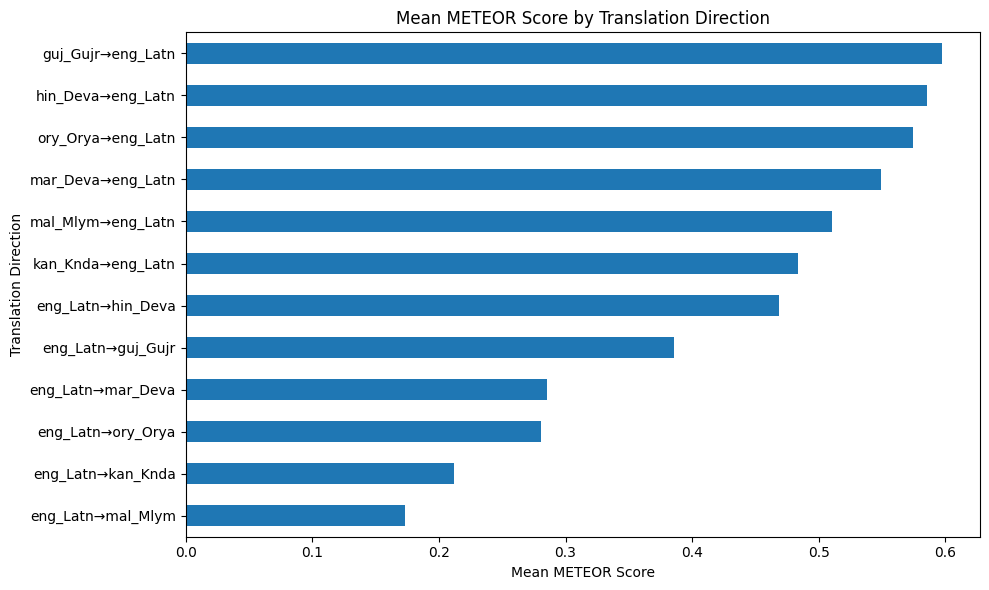

In [24]:
import matplotlib.pyplot as plt

direction_mean = (
    evaluation_data
    .groupby("direction")["meteor_score"]
    .mean()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))
direction_mean.plot(kind="barh")

plt.xlabel("Mean METEOR Score")
plt.ylabel("Translation Direction")
plt.title("Mean METEOR Score by Translation Direction")
plt.tight_layout()
plt.show()

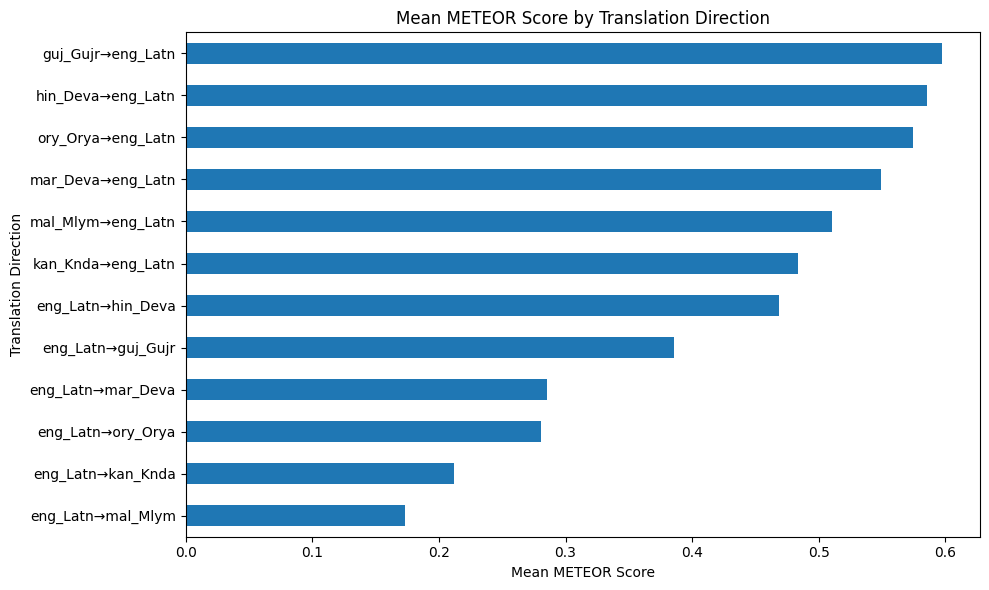

In [25]:
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(10, 6))
direction_mean.plot(kind="barh")

plt.xlabel("Mean METEOR Score")
plt.ylabel("Translation Direction")
plt.title("Mean METEOR Score by Translation Direction")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "meteor_by_direction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
# Lowest METEOR examples
lowest_examples = (
    evaluation_data
    .sort_values("meteor_score")
    [["dataset", "direction", "source", "reference",
      "translation", "meteor_score"]]
    .head(5)
)

display(lowest_examples)

,dataset,direction,source,reference,translation,meteor_score
15947,IN22,eng_Latn→kan_Knda,So cool!,ಒಳ್ಳೆ ಮಜಾ!,ತುಂಬಾ ತಂಪಾಗಿದೆ!,0.0
15974,IN22,eng_Latn→kan_Knda,I used to love her in Son Pari.,ಸೋನ್‌ ಪರೀಯಲ್ಲಿ ಅವ್ರನ್ನ ತುಂಬಾ ಇಷ್ಟ ಪಡ್ತಿದ್ದೆ ನಾನು.,ನಾನು ಅವಳನ್ನು ಸೋನ್ ಪಾರಿನಲ್ಲಿ ಪ್ರೀತಿಸುತ್ತಿದ್ದೆ.,0.0
15968,IN22,eng_Latn→kan_Knda,The veteran ensemble cast delivers such convin...,ಅನುಭವಿ ಕಲಾವಿದವರ್ಗ ಎಷ್ಟು ನಂಬಿಕೆ ಹುಟ್ಟಿಸೋ ಹಾಗೆ ಅ...,ಈ ಹಿರಿಯ ತಂಡವು ಅಂತಹ ಮನವರಿಕೆಯ ಪ್ರದರ್ಶನಗಳನ್ನು ನೀಡ...,0.0
15961,IN22,eng_Latn→kan_Knda,I read that Sumbli also broke down while shoot...,ಕ್ಲೈಮ್ಯಾಕ್ಸ್‌ ಚಿತ್ರೀಕರಿಸೋವಾಗ ಸುಂಬ್ಲಿಯವ್ರೂ ಅತ್ತ...,"ನಾನು ಓದಿದ್ದು, ಶೂಟಿಂಗ್ ಮುಗಿಯುವಾಗ ಸುಂಬಲಿ ಕೂಡ ಮುಳ...",0.0
19803,IN22,eng_Latn→ory_Orya,Please be careful about the news updates.,ଦୟାକରି ତାଜା ଖବର ପ୍ରତି ଦୃଷ୍ଟି ରଖିଥିବେ।,ଖବରକାଗଜରେ ସତର୍କ ରୁହନ୍ତୁ ।,0.0


In [27]:
# Highest METEOR examples
highest_examples = (
    evaluation_data
    .sort_values("meteor_score", ascending=False)
    [["dataset", "direction", "source", "reference",
      "translation", "meteor_score"]]
    .head(5)
)

display(highest_examples)

,dataset,direction,source,reference,translation,meteor_score
40975,IN22,mar_Deva→eng_Latn,भारतीय जैवतंत्रज्ञान नियामक प्राधिकरण (बी.आर.ए...,The Biotechnology Regulatory Authority of Indi...,The Biotechnology Regulatory Authority of Indi...,0.999968
41999,IN22,ory_Orya→eng_Latn,ଭାରତୀୟ ବାୟୋଟେକ୍ନୋଲୋଜି ନିୟାମକ ପ୍ରାଧିକରଣ (ବ୍ରାଇ)...,The Biotechnology Regulatory Authority of Indi...,The Biotechnology Regulatory Authority of Indi...,0.999968
38039,IN22,hin_Deva→eng_Latn,द्वितीय भाग (अनुच्छेद 17-24) सम्मेलन के प्रतिव...,Part II (Articles 17-24) governs the reporting...,Part II (Articles 17-24) governs the reporting...,0.999953
36649,IN22,guj_Gujr→eng_Latn,પ્રવાસન ૨૦મી સદીના સૌથી મોટા વૈશ્વિક ઉદ્યોગ તર...,Tourism emerged as the largest global industry...,Tourism emerged as the largest global industry...,0.999953
6452,FLORES-200,guj_Gujr→eng_Latn,સત્તાનું સંતુલન એક પ્રણાલી હતી જેમાં યુરોપિયન ...,The balance of power was a system in which Eur...,The balance of power was a system in which Eur...,0.999946


In [28]:
# ============================================================
# HIGH-METEOR QUALITATIVE EXAMPLES
# ============================================================

high_examples = (
    evaluation_data
    .sort_values("meteor_score", ascending=False)
    [["dataset", "direction", "source",
      "reference", "translation", "meteor_score"]]
    .head(5)
    .copy()
)

high_examples

,dataset,direction,source,reference,translation,meteor_score
40975,IN22,mar_Deva→eng_Latn,भारतीय जैवतंत्रज्ञान नियामक प्राधिकरण (बी.आर.ए...,The Biotechnology Regulatory Authority of Indi...,The Biotechnology Regulatory Authority of Indi...,0.999968
41999,IN22,ory_Orya→eng_Latn,ଭାରତୀୟ ବାୟୋଟେକ୍ନୋଲୋଜି ନିୟାମକ ପ୍ରାଧିକରଣ (ବ୍ରାଇ)...,The Biotechnology Regulatory Authority of Indi...,The Biotechnology Regulatory Authority of Indi...,0.999968
38039,IN22,hin_Deva→eng_Latn,द्वितीय भाग (अनुच्छेद 17-24) सम्मेलन के प्रतिव...,Part II (Articles 17-24) governs the reporting...,Part II (Articles 17-24) governs the reporting...,0.999953
36649,IN22,guj_Gujr→eng_Latn,પ્રવાસન ૨૦મી સદીના સૌથી મોટા વૈશ્વિક ઉદ્યોગ તર...,Tourism emerged as the largest global industry...,Tourism emerged as the largest global industry...,0.999953
6452,FLORES-200,guj_Gujr→eng_Latn,સત્તાનું સંતુલન એક પ્રણાલી હતી જેમાં યુરોપિયન ...,The balance of power was a system in which Eur...,The balance of power was a system in which Eur...,0.999946


In [29]:
# ============================================================
# LOW-METEOR QUALITATIVE EXAMPLES
# ============================================================

low_examples = (
    evaluation_data
    .sort_values("meteor_score", ascending=True)
    [["dataset", "direction", "source",
      "reference", "translation", "meteor_score"]]
    .head(5)
    .copy()

)

low_examples

,dataset,direction,source,reference,translation,meteor_score
15947,IN22,eng_Latn→kan_Knda,So cool!,ಒಳ್ಳೆ ಮಜಾ!,ತುಂಬಾ ತಂಪಾಗಿದೆ!,0.0
15974,IN22,eng_Latn→kan_Knda,I used to love her in Son Pari.,ಸೋನ್‌ ಪರೀಯಲ್ಲಿ ಅವ್ರನ್ನ ತುಂಬಾ ಇಷ್ಟ ಪಡ್ತಿದ್ದೆ ನಾನು.,ನಾನು ಅವಳನ್ನು ಸೋನ್ ಪಾರಿನಲ್ಲಿ ಪ್ರೀತಿಸುತ್ತಿದ್ದೆ.,0.0
15968,IN22,eng_Latn→kan_Knda,The veteran ensemble cast delivers such convin...,ಅನುಭವಿ ಕಲಾವಿದವರ್ಗ ಎಷ್ಟು ನಂಬಿಕೆ ಹುಟ್ಟಿಸೋ ಹಾಗೆ ಅ...,ಈ ಹಿರಿಯ ತಂಡವು ಅಂತಹ ಮನವರಿಕೆಯ ಪ್ರದರ್ಶನಗಳನ್ನು ನೀಡ...,0.0
15961,IN22,eng_Latn→kan_Knda,I read that Sumbli also broke down while shoot...,ಕ್ಲೈಮ್ಯಾಕ್ಸ್‌ ಚಿತ್ರೀಕರಿಸೋವಾಗ ಸುಂಬ್ಲಿಯವ್ರೂ ಅತ್ತ...,"ನಾನು ಓದಿದ್ದು, ಶೂಟಿಂಗ್ ಮುಗಿಯುವಾಗ ಸುಂಬಲಿ ಕೂಡ ಮುಳ...",0.0
19803,IN22,eng_Latn→ory_Orya,Please be careful about the news updates.,ଦୟାକରି ତାଜା ଖବର ପ୍ରତି ଦୃଷ୍ଟି ରଖିଥିବେ।,ଖବରକାଗଜରେ ସତର୍କ ରୁହନ୍ତୁ ।,0.0


In [30]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/UniMTScore")
INDIC_DIR = PROJECT_ROOT / "datasets" / "IndicMT_Eval"

print("IndicMT-Eval contents:")
for p in INDIC_DIR.iterdir():
    print(p.name)

IndicMT-Eval contents:
train_clean.csv
validation_clean.csv
test_clean.csv


In [31]:
INDIC_DIR = PROJECT_ROOT / "datasets" / "IndicMT_Eval"

for file_name in [
    "train_clean.csv",
    "validation_clean.csv",
    "test_clean.csv"
]:
    path = INDIC_DIR / file_name

    df = pd.read_csv(path)

    print("=" * 70)
    print("FILE:", file_name)
    print("SHAPE:", df.shape)
    print("COLUMNS:", df.columns.tolist())
    print("\nFIRST 2 ROWS:")
    display(df.head(2))

FILE: train_clean.csv
SHAPE: (4997, 6)
COLUMNS: ['src', 'ref', 'translation', 'language', 'mqm_norm_score', 'da_norm_score']

FIRST 2 ROWS:


,src,ref,translation,language,mqm_norm_score,da_norm_score
0,NaN,NaN,NaN,Gujarati,NaN,NaN
1,. Scientists say this animal's plumage was che...,. વૈજ્ઞાનિકો કહે છે કે આ પ્રાણીનું પીંછા ઉપરથી...,એમ.વૈજ્ઞાનિકોનું કહેવું છે કે આ પ્રાણીના પીંછા...,Gujarati,0.9,0.8


FILE: validation_clean.csv
SHAPE: (1000, 6)
COLUMNS: ['src', 'ref', 'translation', 'language', 'mqm_norm_score', 'da_norm_score']

FIRST 2 ROWS:


,src,ref,translation,language,mqm_norm_score,da_norm_score
0,The final match of the series will take place ...,या मालिकेतील अंतिम सामना हा जोहान्सबर्ग येथील ...,पुढील आठवड्यात जोहान्सबर्गच्या एलिस पार्कमध्ये...,Marathi,0.96,0.92
1,The final match of the series will take place ...,या मालिकेतील अंतिम सामना हा जोहान्सबर्ग येथील ...,या मालिकेतील अंतिम सामना पुढील आठवड्यात जोहान्...,Marathi,1.00,1.00


FILE: test_clean.csv
SHAPE: (2380, 6)
COLUMNS: ['src', 'ref', 'translation', 'language', 'mqm_norm_score', 'da_norm_score']

FIRST 2 ROWS:


,src,ref,translation,language,mqm_norm_score,da_norm_score
0,The Chaco region was home to other groups of i...,ਚਾਕੋ ਖੇਤਰ ਦੇਸੀ ਕਬੀਲਿਆਂ ਦੇ ਹੋਰ ਸਮੂਹਾਂ ਜਿਵੇਂ ਗਾਇ...,ਚਾਕੋ ਖੇਤਰ ਸਵਦੇਸ਼ੀ ਕਬੀਲਿਆਂ ਦੇ ਹੋਰ ਸਮੂਹਾਂ ਦਾ ਘਰ ...,Punjabi,0.84,0.4
1,"For instance, they didn't have corn, nor tomat...","ਮਿਸਾਲ ਦੇ ਤੌਰ ‘ਤੇ, ਉਨ੍ਹਾਂ ਕੋਲ ਨਾ ਮੱਕੀ, ਨਾ ਟਮਾਟਰ...","ਉਦਾਹਰਣ ਵਜੋਂ, ਉਨ੍ਹਾਂ ਕੋਲ ਮੱਕੀ, ਨਾ ਟਮਾਟਰ, ਨਾ ਆਲੂ...",Punjabi,0.84,0.6


In [32]:
INDIC_DIR = PROJECT_ROOT / "datasets" / "IndicMT_Eval"

indic_train = pd.read_csv(INDIC_DIR / "train_clean.csv")
indic_val = pd.read_csv(INDIC_DIR / "validation_clean.csv")
indic_test = pd.read_csv(INDIC_DIR / "test_clean.csv")

print("Train:", indic_train.shape)
print("Validation:", indic_val.shape)
print("Test:", indic_test.shape)

Train: (4997, 6)
Validation: (1000, 6)
Test: (2380, 6)


In [33]:
indic_train["subset"] = "train"
indic_val["subset"] = "validation"
indic_test["subset"] = "test"

In [34]:
indic = pd.concat(
    [indic_train, indic_val, indic_test],
    ignore_index=True
)

print("Combined IndicMT-Eval shape:", indic.shape)
print("\nLanguages:")
print(indic["language"].value_counts())

Combined IndicMT-Eval shape: (8377, 7)

Languages:
language
Gujarati     1477
Malayalam    1476
Hindi        1476
Tamil        1475
Marathi      1473
Punjabi       250
Maithili      250
Kannada       250
Assamese      250
Name: count, dtype: int64


In [35]:
# UniMTScore project language scope
PROJECT_LANGUAGES = [
    "Gujarati",
    "Hindi",
    "Kannada",
    "Malayalam",
    "Marathi",
    "Odia"
]

# Keep only project languages available in IndicMT-Eval
indic = indic[
    indic["language"].isin(PROJECT_LANGUAGES)
].copy()

print("IndicMT-Eval after project-language filtering:")
print(indic["language"].value_counts())

print("\nLanguages absent from IndicMT-Eval:")
available_languages = set(indic["language"].dropna().unique())

for lang in PROJECT_LANGUAGES:
    if lang not in available_languages:
        print("-", lang)

IndicMT-Eval after project-language filtering:
language
Gujarati     1477
Malayalam    1476
Hindi        1476
Marathi      1473
Kannada       250
Name: count, dtype: int64

Languages absent from IndicMT-Eval:
- Odia


In [38]:
print(indic.shape)
print(indic.columns.tolist())
print(indic["language"].value_counts())

(6152, 7)
['src', 'ref', 'translation', 'language', 'mqm_norm_score', 'da_norm_score', 'subset']
language
Gujarati     1477
Malayalam    1476
Hindi        1476
Marathi      1473
Kannada       250
Name: count, dtype: int64


In [39]:
indic = indic.rename(
    columns={
        "src": "source",
        "ref": "reference"
    }
)

In [40]:
indic["dataset"] = "IndicMT-Eval"

In [41]:
LANGUAGE_CODES = {
    "Gujarati": "guj_Gujr",
    "Hindi": "hin_Deva",
    "Kannada": "kan_Knda",
    "Malayalam": "mal_Mlym",
    "Marathi": "mar_Deva",
    "Odia": "ory_Orya"
}

indic["source_language"] = indic["language"].map(LANGUAGE_CODES)
indic["target_language"] = "English"

indic["direction"] = (
    indic["source_language"] + "→eng_Latn"
)

In [42]:
indic_final = indic[
    [
        "dataset",
        "subset",
        "source",
        "reference",
        "translation",
        "source_language",
        "target_language",
        "direction",
        "mqm_norm_score",
        "da_norm_score"
    ]
].copy()

print("IndicMT-Eval standardized shape:", indic_final.shape)

display(indic_final.head())

IndicMT-Eval standardized shape: (6152, 10)


,dataset,subset,source,reference,translation,source_language,target_language,direction,mqm_norm_score,da_norm_score
0,IndicMT-Eval,train,NaN,NaN,NaN,guj_Gujr,English,guj_Gujr→eng_Latn,NaN,NaN
1,IndicMT-Eval,train,. Scientists say this animal's plumage was che...,. વૈજ્ઞાનિકો કહે છે કે આ પ્રાણીનું પીંછા ઉપરથી...,એમ.વૈજ્ઞાનિકોનું કહેવું છે કે આ પ્રાણીના પીંછા...,guj_Gujr,English,guj_Gujr→eng_Latn,0.90,0.8
2,IndicMT-Eval,train,. Scientists say this animal's plumage was che...,. વૈજ્ઞાનિકો કહે છે કે આ પ્રાણીનું પીંછા ઉપરથી...,. વૈજ્entistsાનિકોકહે છે કે આ પ્રાણીનું પ્લgeમ...,guj_Gujr,English,guj_Gujr→eng_Latn,0.60,0.6
3,IndicMT-Eval,train,. Scientists say this animal's plumage was che...,. વૈજ્ઞાનિકો કહે છે કે આ પ્રાણીનું પીંછા ઉપરથી...,. વૈજ્ઞાનિકોનું કહેવું છે કે આ પ્રાણીનું પ્લમે...,guj_Gujr,English,guj_Gujr→eng_Latn,0.88,0.8
4,IndicMT-Eval,train,. Scientists say this animal's plumage was che...,. વૈજ્ઞાનિકો કહે છે કે આ પ્રાણીનું પીંછા ઉપરથી...,વૈજ્ઞાનિકોનું કહેવું છે કે આ પ્રાણીની પલમેજ ઉપ...,guj_Gujr,English,guj_Gujr→eng_Latn,0.86,0.8


In [43]:
print("IndicMT-Eval rows by subset:")
print(indic_final["subset"].value_counts())

print("\nIndicMT-Eval rows by language:")
print(indic_final["source_language"].value_counts())

print("\nIndicMT-Eval rows by direction:")
print(indic_final["direction"].value_counts())

IndicMT-Eval rows by subset:
subset
train         3998
test          1354
validation     800
Name: count, dtype: int64

IndicMT-Eval rows by language:
source_language
guj_Gujr    1477
mal_Mlym    1476
hin_Deva    1476
mar_Deva    1473
kan_Knda     250
Name: count, dtype: int64

IndicMT-Eval rows by direction:
direction
guj_Gujr→eng_Latn    1477
mal_Mlym→eng_Latn    1476
hin_Deva→eng_Latn    1476
mar_Deva→eng_Latn    1473
kan_Knda→eng_Latn     250
Name: count, dtype: int64


In [44]:
for file_name in [
    "train_clean.csv",
    "validation_clean.csv",
    "test_clean.csv"
]:
    df = pd.read_csv(INDIC_DIR / file_name)

    print("=" * 60)
    print(file_name)
    print(df["language"].value_counts(dropna=False))

train_clean.csv
language
Gujarati     1001
Malayalam    1000
Hindi        1000
Tamil         999
Marathi       997
Name: count, dtype: int64
validation_clean.csv
language
Marathi      200
Gujarati     200
Malayalam    200
Tamil        200
Hindi        200
Name: count, dtype: int64
test_clean.csv
language
Tamil        276
Marathi      276
Gujarati     276
Hindi        276
Malayalam    276
Punjabi      250
Assamese     250
Maithili     250
Kannada      250
Name: count, dtype: int64


In [45]:
print("FLORES + IN22 shape:", evaluation_data.shape)
print("\nColumns:")
print(evaluation_data.columns.tolist())

print("\nDataset distribution:")
print(evaluation_data["dataset"].value_counts())

print("\nDirection distribution:")
print(evaluation_data["direction"].value_counts())

FLORES + IN22 shape: (42288, 11)

Columns:
['evaluation_id', 'dataset', 'subset', 'source', 'reference', 'translation', 'source_language', 'target_language', 'direction', 'meteor_score', 'direction_type']

Dataset distribution:
dataset
IN22          30324
FLORES-200    11964
Name: count, dtype: int64

Direction distribution:
direction
eng_Latn→guj_Gujr    3524
eng_Latn→hin_Deva    3524
eng_Latn→kan_Knda    3524
eng_Latn→mal_Mlym    3524
eng_Latn→mar_Deva    3524
eng_Latn→ory_Orya    3524
guj_Gujr→eng_Latn    3524
hin_Deva→eng_Latn    3524
kan_Knda→eng_Latn    3524
mal_Mlym→eng_Latn    3524
mar_Deva→eng_Latn    3524
ory_Orya→eng_Latn    3524
Name: count, dtype: int64


In [48]:
base_eval = evaluation_data[
    [
        "evaluation_id",
        "dataset",
        "subset",
        "source",
        "reference",
        "translation",
        "source_language",
        "target_language",
        "direction"
    ]
].copy()

print("Base:", base_eval.shape)

Base: (42288, 9)


In [49]:
indic_eval = indic[
    [
        "dataset",
        "subset",
        "source",
        "reference",
        "translation",
        "source_language",
        "target_language",
        "direction"
    ]
].copy()

print("IndicMT:", indic_eval.shape)

IndicMT: (6152, 8)


In [50]:
indic_eval.insert(
    0,
    "evaluation_id",
    range(
        len(base_eval) + 1,
        len(base_eval) + len(indic_eval) + 1
    )
)

print(indic_eval.shape)
print(indic_eval["evaluation_id"].min())
print(indic_eval["evaluation_id"].max())

(6152, 9)
42289
48440


In [51]:
unified_eval = pd.concat(
    [base_eval, indic_eval],
    ignore_index=True
)

print("FINAL SHAPE:", unified_eval.shape)

print("\nDataset distribution:")
print(unified_eval["dataset"].value_counts())

FINAL SHAPE: (48440, 9)

Dataset distribution:
dataset
IN22            30324
FLORES-200      11964
IndicMT-Eval     6152
Name: count, dtype: int64


In [52]:
unified_eval["meteor_score"] = unified_eval.apply(
    lambda row: calculate_meteor(
        row["reference"],
        row["translation"]
    ),
    axis=1
)

print(unified_eval["meteor_score"].describe())

count    48439.000000
mean         0.419831
std          0.248023
min          0.000000
25%          0.214784
50%          0.418944
75%          0.609504
max          0.999968
Name: meteor_score, dtype: float64


In [53]:
print(unified_eval["meteor_score"].describe())

count    48439.000000
mean         0.419831
std          0.248023
min          0.000000
25%          0.214784
50%          0.418944
75%          0.609504
max          0.999968
Name: meteor_score, dtype: float64


In [54]:
dataset_stats = (
    unified_eval
    .groupby("dataset")["meteor_score"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .round(4)
)

display(dataset_stats)

,count,mean,median,std,minimum,maximum
dataset,,,,,,
FLORES-200,11964,0.4722,0.4811,0.2249,0.0,0.9999
IN22,30324,0.4071,0.4047,0.2585,0.0,1.0000
IndicMT-Eval,6151,0.3809,0.3699,0.2212,0.0,0.9999


In [55]:
direction_stats = (
    unified_eval
    .groupby("direction")["meteor_score"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .round(4)
)

display(direction_stats)

,count,mean,median,std,minimum,maximum
direction,,,,,,
eng_Latn→guj_Gujr,3524,0.3859,0.3766,0.2054,0.0,0.9997
eng_Latn→hin_Deva,3524,0.4685,0.4775,0.2080,0.0,0.9998
eng_Latn→kan_Knda,3524,0.2116,0.1667,0.1866,0.0,0.9922
eng_Latn→mal_Mlym,3524,0.1729,0.1250,0.1656,0.0,0.9960
eng_Latn→mar_Deva,3524,0.2857,0.2573,0.1893,0.0,0.9993
eng_Latn→ory_Orya,3524,0.2804,0.2646,0.1697,0.0,0.9993
guj_Gujr→eng_Latn,5000,0.5404,0.5515,0.2260,0.0,1.0000
hin_Deva→eng_Latn,5000,0.5566,0.5749,0.2219,0.0,1.0000
kan_Knda→eng_Latn,3774,0.4777,0.4937,0.2336,0.0,0.9999


In [56]:
OUTPUT_FILE = PROJECT_ROOT / "features" / "lexical" / "unified_meteor.csv"

unified_eval.to_csv(
    OUTPUT_FILE,
    index=False
)

print("Saved successfully:", OUTPUT_FILE)
print("Final shape:", unified_eval.shape)

Saved successfully: /content/drive/MyDrive/UniMTScore/features/lexical/unified_meteor.csv
Final shape: (48440, 10)


In [57]:
final_meteor = pd.read_csv(OUTPUT_FILE)

print("Reloaded shape:", final_meteor.shape)

print("\nDatasets:")
print(final_meteor["dataset"].value_counts())

print("\nMissing METEOR:")
print(final_meteor["meteor_score"].isna().sum())

print("\nDuplicate IDs:")
print(final_meteor["evaluation_id"].duplicated().sum())

Reloaded shape: (48440, 10)

Datasets:
dataset
IN22            30324
FLORES-200      11964
IndicMT-Eval     6152
Name: count, dtype: int64

Missing METEOR:
1

Duplicate IDs:
0


In [58]:
# ============================================================
# FINAL NOTEBOOK 03 — METEOR SUMMARY
# ============================================================

print("=" * 70)
print("NOTEBOOK 03 — FINAL METEOR EVALUATION")
print("=" * 70)

print(f"\nTotal evaluation instances: {len(final_meteor):,}")
print(f"Datasets: {final_meteor['dataset'].nunique()}")
print(f"Translation directions: {final_meteor['direction'].nunique()}")

print("\nOverall METEOR statistics:")
print(
    final_meteor["meteor_score"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(4)
)

print("\n" + "=" * 70)
print("DATASET-WISE METEOR")
print("=" * 70)

dataset_meteor = (
    final_meteor
    .groupby("dataset")["meteor_score"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .round(4)
)

display(dataset_meteor)

print("\n" + "=" * 70)
print("DIRECTION-WISE METEOR")
print("=" * 70)

direction_meteor = (
    final_meteor
    .groupby("direction")["meteor_score"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .round(4)
)

display(direction_meteor)

NOTEBOOK 03 — FINAL METEOR EVALUATION

Total evaluation instances: 48,440
Datasets: 3
Translation directions: 12

Overall METEOR statistics:
count     48439.0000
mean          0.4198
median        0.4189
std           0.2480
min           0.0000
max           1.0000
Name: meteor_score, dtype: float64

DATASET-WISE METEOR


,count,mean,median,std,minimum,maximum
dataset,,,,,,
FLORES-200,11964,0.4722,0.4811,0.2249,0.0,0.9999
IN22,30324,0.4071,0.4047,0.2585,0.0,1.0000
IndicMT-Eval,6151,0.3809,0.3699,0.2212,0.0,0.9999



DIRECTION-WISE METEOR


,count,mean,median,std,minimum,maximum
direction,,,,,,
eng_Latn→guj_Gujr,3524,0.3859,0.3766,0.2054,0.0,0.9997
eng_Latn→hin_Deva,3524,0.4685,0.4775,0.2080,0.0,0.9998
eng_Latn→kan_Knda,3524,0.2116,0.1667,0.1866,0.0,0.9922
eng_Latn→mal_Mlym,3524,0.1729,0.1250,0.1656,0.0,0.9960
eng_Latn→mar_Deva,3524,0.2857,0.2573,0.1893,0.0,0.9993
eng_Latn→ory_Orya,3524,0.2804,0.2646,0.1697,0.0,0.9993
guj_Gujr→eng_Latn,5000,0.5404,0.5515,0.2260,0.0,1.0000
hin_Deva→eng_Latn,5000,0.5566,0.5749,0.2219,0.0,1.0000
kan_Knda→eng_Latn,3774,0.4777,0.4937,0.2336,0.0,0.9999


In [59]:
highest = direction_meteor["mean"].idxmax()
lowest = direction_meteor["mean"].idxmin()

print("Highest-scoring direction:")
print(highest, "→", direction_meteor.loc[highest, "mean"])

print("\nLowest-scoring direction:")
print(lowest, "→", direction_meteor.loc[lowest, "mean"])

Highest-scoring direction:
ory_Orya→eng_Latn → 0.5746

Lowest-scoring direction:
eng_Latn→mal_Mlym → 0.1729


In [60]:
dataset_meteor.to_csv(
    PROJECT_ROOT / "results" / "meteor_dataset_summary.csv"
)

direction_meteor.to_csv(
    PROJECT_ROOT / "results" / "meteor_direction_summary.csv"
)

print("Summary tables saved successfully.")

Summary tables saved successfully.


In [61]:
print(dataset_meteor)
print(direction_meteor)

              count    mean  median     std  minimum  maximum
dataset                                                      
FLORES-200    11964  0.4722  0.4811  0.2249      0.0   0.9999
IN22          30324  0.4071  0.4047  0.2585      0.0   1.0000
IndicMT-Eval   6151  0.3809  0.3699  0.2212      0.0   0.9999
                   count    mean  median     std  minimum  maximum
direction                                                         
eng_Latn→guj_Gujr   3524  0.3859  0.3766  0.2054      0.0   0.9997
eng_Latn→hin_Deva   3524  0.4685  0.4775  0.2080      0.0   0.9998
eng_Latn→kan_Knda   3524  0.2116  0.1667  0.1866      0.0   0.9922
eng_Latn→mal_Mlym   3524  0.1729  0.1250  0.1656      0.0   0.9960
eng_Latn→mar_Deva   3524  0.2857  0.2573  0.1893      0.0   0.9993
eng_Latn→ory_Orya   3524  0.2804  0.2646  0.1697      0.0   0.9993
guj_Gujr→eng_Latn   5000  0.5404  0.5515  0.2260      0.0   1.0000
hin_Deva→eng_Latn   5000  0.5566  0.5749  0.2219      0.0   1.0000
kan_Knda→eng_Latn   